# 第13回 SQL(データベースとSQLの基礎)

## 1 この章の概要
ゴール：データベースの役割を知る

### 1.1 データベースとは
キーワード：データベース、RDBMS

ここからはデータベースについて学んでいきます。データベースとは、簡単にいいますと、コンピューターを利用して膨大なデータをまとめて、後から色々なニーズに対して活用できるように、管理されたデータの集まりのことです。データベースには、通常複数のテーブルがあり、各テーブルにデータが格納されます。テーブルは行と列で構成され、行はレコード、列はカラムと呼ばれます。データベース、テーブル、レコード、カラムの関係性を示す図は以下を参照ください。

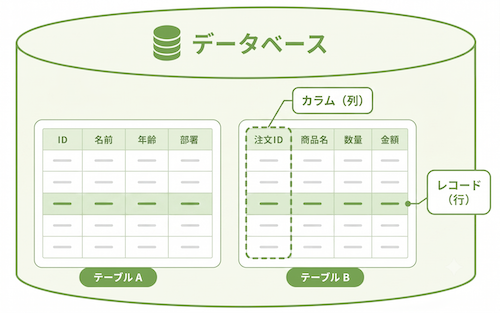

具体的なデータとしては、ある店舗の毎日の売り上げをデータベースで管理していることもありますし、顧客の個人情報、社員の給料情報、金融の取引データ、ウェブサイトのアクセスログデータ等もデータベースで管理されたりしています。購買データでいうと、売れた商品の日時、その商品を識別するコード、購買者、その商品の値段、数量などがデータとしてテーブルに入ってきます。これらのデータは日々追加されますし、何かの集計（1ヶ月の売り上げの計算など）をするときはデータベースからデータが抽出され、必要なければ削除されます。

それでは、そもそも何故データベースが必要なのでしょうか。小さなデータで、一貫性等を求められていなければ、Excelで十分かもしれません。しかし、データは日々大きくなっていきますし、昨今は特にIoTなどが注目されており、リアルタイムに膨大な量のデータが生まれています。ビッグデータと言われる現代、データソースのテーブルに1億レコード以上あるということもしばしばあり、これをExcelで集計することは困難でしょう。データベースとそれを呼び出すためのSQLという言語を使うことで、大きなデータに対しても効率的に作業ができるのです。（ただし、昨今はビッグデータを扱う際にHadoopやSparkなどの分散処理をするソフトウェアなどが使われるようになっており、この講座でも後半の章で少し触れます。）

さらに管理するという視点でも、Excelでは限界があります。Excelは基本的に誰でも編集ができますし、後からデータに問題があった場合に対処するのが困難です。列も自由に異なるデータを入力できますし、それを統一的に扱うのは難しいです。データベースを使うことで、容易に管理できます。なお、同時にデータを変更することを避けるために、データにロックをかけて、他の人が編集できないようにすることを「排他制御」といい、以下のようなイメージ図になります。

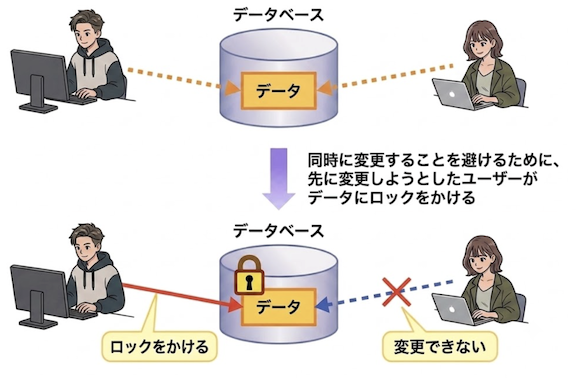

### 1.2 RDBMS（Relational DataBase Management System）
キーワード：RDBMS、MySQL、テーブル

この章で学ぶデータベースのシステムは、RDBMSと言われるリレーショナルデータベースを管理するシステムです。代表的な製品に、Oracle, Microsoft SQL Server, PostgreSQL, MySQLなどがあります。ここでは、DuckDBというデータベースを使用します。

なお、DuckDBの参考サイトは以下になりますので、適宜参照してください。

参照URL：https://duckdb.org/

データベースにはテーブルがあり、データはそのテーブルから抽出します。テーブルは幾つかのカラム（列）から構成され、それぞれ型の異なるデータが入っています。数値型であったり、文字であったり、日時であったりします。Excelでは、同じ列に数字や文字など、色々な型のデータを混在して入れることができますが、データベースのテーブルには同じ型を指定してデータを入れる必要があります。データがそのような状態なので、後で集計がとても簡単にできます。それらの扱い方についても、後で学びます。

ここでデータベースに関する簡単な紹介は終わります。他にも色々な概念がありますが、まずはデータをハンドリングできるように、実装中心に学んでいきましょう。SQLもまた手を動かしながら学ぶことで、早く使えるようになります。

なお、以下の参考文献が初心者にはわかりやすいので、全くSQLの経験がない方は前半のみ一読をおすすめします。一部、PHPとその連携もありますが、この講座を理解するためには必要ありません。適宜、興味があれば学習して、何か簡単なウェブサービスを作ってみるのもデータベースの大変よい理解になります。

>[参考文献]
>
>『基礎からのMySQL 改訂版 (基礎からシリーズ) 』（西沢 夢路 (著)、 SBクリエイティブ）

## 2 SQLの基礎
ゴール：SQLの基礎的な操作方法を身につける

### 2.0 Google colabでSQLを使うための設定

必要なモジュールをダウンロードします

In [ ]:
# IPython用のモジュールをダウンロード
!pip install jupysql duckdb-engine

データ読み込みとデータベースの設定をします。

In [ ]:
%load_ext sql
%sql duckdb://

以降、セルごとにマジックコマンド

```
%%sql
```
を先頭に付けることで、SQLクエリを実行できます。


**※「"」（ダブルクォーテーション）は使えません。「'」（シングルクォーテーション）を使用してください。**

また、SQLでは大文字と小文字は区別されませんが、コードの可読性と視認性を高めるために、以下のような慣例が広く用いられています。
*   予約語（SELECT、FROM、WHERE、JOIN等）は大文字で記述する
*   テーブル名やカラム名は小文字で記述する
*   複数の単語からなるテーブル名やカラム名はアンダースコア（_）で区切る



### 2.1 データベースとテーブルの作成
キーワード：データベース作成、テーブル、SHOW DATABASES, USE, SHOW TABLES, CREATE, SELECT

** 注意：以下、練習問題も含め、可能な限り上から実行するようにしてください。あとの問題で使います。**

テーブルを作成していきます。テーブルにデータが入り、データのカラム名とその型を指定します。実際にテーブルを作ってみましょう。以下のようにCREATE TABLEを実行しますが、要注意です。最初にテーブル名、データの型と名前等を付けています。ここではmeiboテーブルに整数型のid、文字型のnameを設定しています。さらに、PRIMARY KEYというのは、このカラムが一意のキーとなっていることを宣言しています。つまり、同じデータは入らないということです。

In [ ]:
%%sql
CREATE TABLE meibo
  (id INT PRIMARY KEY, name VARCHAR(20))

さて、ここでテーブルからデータを引っ張る時に、以下のようにSELECT * FROM テーブル名という書き方をします。アスタリスクは、すべての列名を持ってくるという意味です。ただ、以下のSELECT文を実行しても、空のテーブルだけなので、中身は何もなく、空のレコードが表示されます。

In [ ]:
%%sql
SELECT * FROM meibo;

用意したテーブルに、データを挿入してみましょう。データの挿入はINSERT INTO を使います。その後に、「テーブル名（カラム名）VALUES 挿入したいデータ」で実行します。以下のように記述して、データを3レコード挿入しています。

In [ ]:
%%sql
INSERT INTO meibo (id, name) VALUES (1, 'Yamada'); # ※シングルクオーテーションマークを使用してください

In [ ]:
%%sql
INSERT INTO meibo (id, name) VALUES (2, 'Tanaka');

In [ ]:
%%sql
INSERT INTO meibo (id, name) VALUES (3, 'Sato');

もう一度、テーブルを確認してみましょう。

In [ ]:
%%sql
SELECT * FROM meibo;

なお、同じキーとなるidのデータを入れるとエラーが出て、以下のようになります。

In [ ]:
%%sql
INSERT INTO meibo (id, name) VALUES (1, 'Yamada');

In [ ]:
#上のセルで発生したエラー（トランザクション）の中断状態を一旦解除する
#これが無いと、以降のコードがエラーで機能しなくなる。※他には、ランタイムの接続を解除し上から実行しなおす方法もある。

%%sql
ROLLBACK;


以下のSQLでテーブルの一覧を確認できます。

In [ ]:
%%sql
SELECT name FROM sqlite_master WHERE type='table';

>**[ポイント]**
>
>CREATE DATABASES [データベース名]：データベースの作成
>
>CREATE TABLE [テーブル名] [カラム名 型]：テーブルの作成
>
>CREATE TABLE [テーブル名] [カラム名 型] PRIMARY KEY：プライマリーキーの設定
>
>SELECT * FROM テーブル名：テーブル名のカラムすべてのデータを問い合わせ
>
>INSERT INTO [テーブル名] [カラム名 型] [値]：データの挿入

#### <練習問題 1>
新しいテーブル「meibo2」を作成してください。作成後はテーブルが完成しているか、確認しましょう。データのカラム名とその型はなんでも構いません。

In [ ]:
%%sql
CREATE TABLE meibo2
  (id INT PRIMARY KEY, name VARCHAR(20))

In [ ]:
%%sql
SELECT name FROM sqlite_master WHERE type='table';

#### <練習問題 2>

練習1で新しく作ったテーブルmeibo2にデータを追加してみましょう。追加後は、確かにデータが入っているか確認してください。

In [ ]:
%%sql
INSERT INTO meibo2 (id, name) VALUES (1, 'Yamada');

In [ ]:
%%sql
SELECT * FROM meibo2;

### 2.2 データの検索と更新、削除、テーブルカラムの変更
キーワード：WHERE, IN, LIKE, UPDATE, DELETE, ALTER

次は、データの抽出をするときに、条件を絞って実行してみましょう。条件はWHERE文を使います。以下では、id=2の人のデータを抽出しています。

In [ ]:
%%sql
SELECT * FROM meibo WHERE id=2;

次は、INを使うことでidが1か2であるレコードを抽出します。（他、データの範囲を絞り込むためBETWEENなどもありますので、調べてみてください。）

In [ ]:
%%sql
SELECT * FROM meibo WHERE id IN (1,2);

以下のような記述で、曖昧検索もできます。LIKEを使って、以下の処理では、Sからはじまって後は任意の文字列ということで、「S%」としています。他にも、「%S」や「%S%」で検索が可能です。

In [ ]:
%%sql
SELECT * FROM meibo WHERE name LIKE 'S%';

>**[やってみよう]**
>
>上の条件式を色々と変更してデータを検索してみましょう。例えば、idが1以外の人や、nameがaで終わる人はどのように検索しますか？

今までは存在するデータを抽出してきましたが、次はデータを変更してみます。UPDATEを使って、id=3の人を更新してみます。記述方法は以下のようになります。

In [ ]:
%%sql
UPDATE meibo
SET name = 'Suzuki'
WHERE id=3;

更新されているか確かめてみましょう。

In [ ]:
%%sql
SELECT * FROM meibo;

データを削除する場合も扱いましょう。削除用のサンプルデータを用意(id=4)して、確認します。

In [ ]:
%%sql
INSERT INTO meibo (id, name) VALUES (4, 'Dummy');

In [ ]:
%%sql
SELECT * FROM meibo;

データの削除はDELETEを使います。ここでは、先ほど用意しましたid＝4の人を削除します。

In [ ]:
%%sql
DELETE FROM meibo
WHERE id = 4;

念のため、消えているかどうか確認しましょう。

In [ ]:
%%sql
SELECT * FROM meibo;

次は、新しいカラムを追加しましょう。その人のクラスと年齢を追加します。「ALTER TABLE テーブル名 ADD 新しいカラム名 型」です。

In [ ]:
%%sql
ALTER TABLE meibo ADD class INT;

In [ ]:
%%sql
ALTER TABLE meibo ADD age INT;

新しくカラムを追加したテーブルをチェックしてみましょう。classカラムとageカラムには、まだ何もデータは入っていないので、値は空（None）になります。  

In [ ]:
%%sql
SELECT * FROM meibo;

UPDATEを使ってデータを更新します。

In [ ]:
%%sql
UPDATE meibo
SET class=1,age=13
WHERE id=3;

id=3の人のレコードにクラスと年齢のデータが入りました。

In [ ]:
%%sql
SELECT * FROM meibo;

続けて、他の人のデータも更新しましょう。

In [ ]:
%%sql
UPDATE meibo
SET class=1,age=14
WHERE id=1;

In [ ]:
%%sql
UPDATE meibo
SET class=2,age=13
WHERE id=2;

In [ ]:
%%sql
SELECT * FROM meibo;

新しい人たちのデータを追加しましょう。先ほどはINSERTを1つ1つ実行していきました。ここでは、以下のコマンドで一度に追加します。

In [ ]:
%%sql
INSERT INTO meibo (id,name,class,age)
VALUES (4,'Kato',2,15),(5,'Ito',3,12),(6,'Takeuchi',2,16),(7,'Kimura',3,11),(8,'Sato',1,14);

データの確認をします。

In [ ]:
%%sql
SELECT * FROM meibo;

>**[ポイント]**
>
>SELECT * FROM [テーブル名] WHERE 条件：条件でデータを絞り込み
>
>IN：条件マッチ
>
>LIKE：曖昧検索
>
>DELETE FROM [テーブル名]：データの削除（注：条件を絞りこむ場合はWHERE文を追加する）
>
>ALTER TABLE [テーブル名] ADD [カラム名 型]:テーブルのカラム名追加
>
>UPDATE [テーブル名] SET ：データのアップデート

#### <練習問題 1>
上記のテーブルmeiboにて、id=4の人レコードを抽出してください。

In [ ]:
%%sql
SELECT * FROM meibo WHERE id = 4;

#### <練習問題 2>

上のmeiboテーブルでid=8の人のclassを7にアップデートしてください。select文でアップデートを確認できたら、id=8の人のclassを1に戻してください。

In [ ]:
%%sql
SELECT * FROM meibo WHERE id = 8;

In [ ]:
%%sql
UPDATE meibo
SET class = 7
WHERE id=8;

In [ ]:
%%sql
SELECT * FROM meibo WHERE id = 8;

In [ ]:
%%sql
UPDATE meibo
SET class = 1
WHERE id=8;

In [ ]:
%%sql
 SELECT * FROM meibo WHERE id = 8;

#### <練習問題 3>　(※必須問題：以降の問題で使います。)

上記と同じテーブルmeiboに新しい列heightという身長のカラムを追加してください。さらに、id=1から4までの人は150、id=5から6までの人は155、id=7から8までの人は160でアップデートしてください。

In [ ]:
%%sql
ALTER TABLE meibo ADD height INT;

In [ ]:
%%sql
UPDATE meibo
SET height=150
WHERE id<=4;

In [ ]:
%%sql
UPDATE meibo
SET height=155
WHERE id>=5 AND id<=6;

In [ ]:
%%sql
UPDATE meibo
SET height=160
WHERE id>=7;

In [ ]:
%%sql
SELECT * FROM meibo;

### 2.3 データの集計、演算、並び替え
キーワード：COUNT, DISTINCT, ORDER, AVG, SUM, LIMIT


次は、SQLを使った集計になります。データを見るときにまず気になるのが、何レコードあるかということです。以下で、データが何行あるかカウントするために、COUNT関数を使っています。

In [ ]:
%%sql
SELECT COUNT(*) FROM meibo;

なお、AS句を使うことで集計結果のカラムに別名（エイリアス）をつけることができます。ここでは、COUNT(*)の結果にcntという別名（エイリアス）を付けています。

In [ ]:
%%sql
SELECT COUNT(*) AS cnt FROM meibo;

次は、このCOUNT関数を使って、異なる種類のデータを数えてみます。具体的には、先ほどレコード数は8レコードありましたが、異なるクラスは何クラスあるでしょうか。COUNT関数とDISTINCTを組み合わせることで、重複を除いた値の個数をカウントできます。ここでは、meiboテーブルに含まれる異なるクラスの数をカウントします。

In [ ]:
%%sql
SELECT COUNT(DISTINCT class) AS classCnt FROM meibo;

次は、平均を計算します。以下は、平均年齢を計算しています。AVG関数を使います。

In [ ]:
%%sql
 SELECT AVG(age) AS avgAge FROM meibo;

なお、SUM関数を使うと合計されますが、年齢の合計の用途はあまりなさそうです。ここでは、先ほどのCOUNT関数と組み合わせて、平均年齢を算出しましょう。上記の結果と同じになっていることがわかります。このように、SELECTの中で演算が可能です。

In [ ]:
%%sql
SELECT CAST(SUM(age) AS REAL) / CAST(COUNT(*) AS REAL) AS avgAge FROM meibo;

MIN関数とMAX関数を使うと、それぞれ最小値と最大値を求めることができます。ここでは、年齢の最小値と最大値を求めます。
<br>
（最年少が11歳、最年長が16歳とわかります。）

In [ ]:
%%sql
SELECT MIN(age) AS minAge, MAX(age) AS maxAge FROM meibo;

次は、idを軸として降順に並べてみましょう。並び替えはORDER BY カラム名を使います。 DESCをつけることで、降順（大きいものから小さいものの順番）になります。

In [ ]:
%%sql
SELECT * FROM meibo ORDER BY id DESC;

今度は、ageを軸として昇順（小さいものから大きいものの順番）に並べてみましょう。デフォルトは昇順です。

In [ ]:
%%sql
SELECT * FROM meibo ORDER BY age;

複数のカラムを指定してソートすることもできます。ここでは、classとageの2つのカラムを軸に昇順にソートします。
<br>
ソートの優先順位は、ORDER BY句に指定したカラムの順序になります。
<br>
この例では、まずclassでソートされ、次にclassが同じであるレコードがageでソートされます。

In [ ]:
%%sql
SELECT * FROM meibo ORDER BY class, age;

LIMITを使うと行数の制限ができます。大量のデータがある場合は、LIMITを使って表示数を制限すると便利です。

In [ ]:
%%sql
SELECT * FROM meibo LIMIT 3;

WHEREで複数の条件を指定してレコードを絞り込むことができます。AND演算子を使うと、同時条件を満たすレコードを抽出できます。

In [ ]:
%%sql
SELECT * FROM meibo WHERE class=2 AND age>=15;

次は、OR です。どちらか片方の条件を満たすものを絞り込む場合に使います。

In [ ]:
%%sql
SELECT * FROM meibo WHERE class=1 OR age>=15;

>**[ポイント]**
>
>COUNT：レコードのカウント
>
>AS：エイリアス（名前をつける）
>
>DISTINCT ：重複なく区別する
>
>AVG ：平均値
>
>MAX ：最大値
>
>MIN ：最小値
>
>ORDER BY カラム名：昇順に並び替え（降順はカラム名の後にDESC）

#### <練習問題 1>
上記と同じmeiboテーブルで、異なる年齢は何種類でしょうか。

In [ ]:
%%sql
SELECT COUNT(DISTINCT age) AS ageCnt FROM meibo;

#### <練習問題 2>
身長が一番小さい人、大きい人の身長をそれぞれ求めてください。

In [ ]:
%%sql
SELECT MIN(height) AS minHeight, MAX(height) AS maxHeight FROM meibo;

#### <練習問題 3>
身長が155以上で、classが3のレコードを抽出してください。



In [ ]:
%%sql
SELECT * FROM meibo WHERE height>=155 AND class=3;

### 2.4 グループごとの集計
キーワード：GROUP BY, HAVING

次は、SQLを使ってグループごとに集計してみましょう。
<br>
GROUP BYを使うことで、指定したカラムの値ごとに集計を行うことができます。これはExcelのピボットテーブルの機能に似ています。
<br>
ここでは、classを軸として、各クラスの人数をカウントします。

In [ ]:
%%sql
SELECT class, COUNT(*) AS num FROM meibo GROUP BY class;

GROUP BYと組み合わせて、平均を各グループごとに算出することも可能です。
<br>
AVG、MIN、MAXなどの集計関数を使用することで、グループごとの平均値、最小値、最大値などを計算できます。

In [ ]:
%%sql
SELECT class, COUNT(*) AS num, AVG(age) AS avgAge FROM meibo GROUP BY class;

さらに条件付きで表示してみましょう。
<br>
HAVINGを使うことで、GROUP BYでグループ化された結果に対して条件を指定できます。
<br>
ここでは、平均年齢が13より大きいクラスのみを表示します。

In [ ]:
%%sql
SELECT class, AVG(age) AS avgAge FROM meibo GROUP BY class HAVING avgAge>13;

WHEREとHAVINGを組み合わせて使用することもできます。

In [ ]:
%%sql
SELECT class, AVG(age) AS avgAge FROM meibo WHERE age > 13 GROUP BY class;

WHEREとHAVINGはどちらも絞り込むために使いますが、処理されるタイミングが異なります。

WHEREはGROUP BYで集計される前に条件を適用し、HAVINGはGROUP BYで集計された後の結果グループに対して条件を適用します。

次は、2つの軸を使った集計です。
<br>
複数のカラムをGROUP BY句に指定することで、複数の軸で集計できます。
<br>
ここでは、classとageの2つのカラムでグループ化し、各グループのレコード数をカウントします。
<br>
※クラス×年齢でレコード数をカウント

In [ ]:
%%sql
SELECT class, age, COUNT(*) AS num FROM meibo GROUP BY class, age;

番号（順）で指定して集計することも可能です。なお、GROUP BY は以下のように、呼び出している列の番号で指定することもできます。ただし、わからなくなる可能性がありますので、簡易集計以外のときにはカラム名を指定することをおすすめします。

In [ ]:
%%sql
SELECT class, age, COUNT(*) AS num FROM meibo GROUP BY 1, 2;

>**[ポイント]**
>
>GROUP BY：軸を設定
>
>HAVING：条件設定

#### <練習問題 1>

meiboテーブルにてクラスごとの平均身長を求めてみましょう。

In [ ]:
#解答
%%sql
SELECT class, AVG(height) AS avgHeight FROM meibo GROUP BY class;

#### <練習問題 2>

上に加えて、クラスごとの人数、一番小さい人と、一番大きな人の身長もそれぞれのクラスで算出しましょう。

In [ ]:
#解答
%%sql
SELECT class, COUNT(*) AS cnt, MIN(height) AS minHeight, MAX(height) AS maxHeight FROM meibo GROUP BY class;

#### <練習問題 3>

年齢が13歳より上の人に絞って、上記と同じ項目を求めてください。

In [ ]:
#解答
%%sql
SELECT class, COUNT(*) AS cnt, MIN(height) AS minHeight, MAX(height) AS maxHeight FROM meibo WHERE age > 13 GROUP BY class;

### 2.5 複数テーブルの利用
キーワード：UNION, UNION ALL, INNER JOIN(内部結合), OUTER JOIN(外部結合), 自己結合


次は複数のテーブルを使ったデータ操作について学びましょう。
<br>
ここでは、すでに作成したテーブルからデータをコピーして新しいテーブルを作成します。
<br>
CREATE TABLE ... AS SELECT ...文を使うと、SELECT文の結果を新しいテーブルに挿入できます。

In [ ]:
#前の練習問題で作成したテーブルは使わないので、一旦削除します
%%sql
DROP TABLE IF EXISTS meibo2;

In [ ]:
#class=10000は存在しないため、レコードは０
%%sql
CREATE TABLE meibo2 AS SELECT * FROM meibo WHERE class=10000;

確認してみましょう。

In [ ]:
#データの確認
%%sql
SELECT * FROM  meibo2;

meibo2テーブルにデータを挿入します。
<br>
なお、１行目はあえてmeiboにある同じデータ（Yamada）を入れています。結果を確認してみてください。

In [ ]:
%%sql
INSERT INTO meibo2 (id, name, class, age, height)
VALUES (1,'Yamada',1,14,150),
       (9,'Nagata',4,11,160),
       (10,'Sugino',2,13,150),
       (11,'Takayama',1,14,155),
       (12,'John',3,16,165);

In [ ]:
%%sql
 SELECT * FROM  meibo2;

データを結合してみましょう。UNIONを使います。なお、UNIONは重複レコードは省きますが、UNION ALLは重複も許容します。id=1の人がUNION ALLの場合2レコードあるのがわかります。

In [ ]:
%%sql
SELECT * FROM meibo
UNION
SELECT * FROM meibo2;

In [ ]:
%%sql
SELECT * FROM meibo
UNION ALL
SELECT * FROM meibo2;

テストのスコアテーブルを作成して、このmeiboテーブルと結合してみましょう。

In [ ]:
%%sql
CREATE TABLE score
  (id INT PRIMARY KEY, math INT, english INT, science INT);

scoreテーブルにサンプルデータを挿入します。

In [ ]:
%%sql
INSERT INTO score (id, math, english, science)
VALUES (1,10,10,40),(2,NULL,60,100),(3,30,40,60),
       (5,25,31,10),(6,50,30,10),(8,90,100,90),
       (9,67,71,50),(11,100,40,88),(15,76,21,13);

念のためデータが入っているかどうか確認します。

In [ ]:
%%sql
SELECT * FROM score;

JOINを使って、2つのテーブルを結合できます。
<br>
ONで結合条件を指定します。ここでは、meiboテーブルとscoreテーブルをidカラムをキーとして内部結合しています。
<br>
テーブル名に別名（エイリアス）を付けることで、クエリを簡潔に記述できます。
<br>
※テーブル名の後に別名（エイリアス）を簡単に付けています。（meiboはa、scoreはb）

In [ ]:
%%sql
SELECT * FROM meibo a JOIN score b ON a.id=b.id;

LEFT JOINを使うと、左外部結合を実行できます。
<br>
左側のテーブルの全てのレコードと、結合条件を満たす右側のテーブルのレコードが結合されます。
<br>
右側のテーブルに該当するレコードがない場合は、None(NULL)が返されます。

In [ ]:
%%sql
SELECT * FROM meibo a LEFT JOIN score b ON a.id=b.id;

以下は、参考ですが、自分自身のテーブルと結合をする自己結合も可能です。

In [ ]:
%%sql
SELECT * FROM meibo a JOIN meibo b ON a.id=b.id;

>**[ポイント]**
>
>UNION：重複を除いた結合
>
>UNION ALL：重複ありの結合
>
>INNER JOIN：内部結合
>
>LEFT OUTER JOIN：外部結合

#### <練習問題 1>

新しくcardtbというテーブルを作成してください。ただし、カラムはid, point, money (すべてINT)を作成してください。さらに、以下のデータを挿入してください。
<br>(id,point,money) = (1,100,1000),(3,50,500),(4,30,600),(5,10,10),(7,100,1000),(8,2000,100)

In [ ]:
#解答
%%sql
CREATE TABLE cardtb
  (id INT PRIMARY KEY, point INT, money INT);

In [ ]:
#解答
%%sql
INSERT INTO cardtb (id, point, money)
VALUES (1,100,1000),(3,50,500),(4,30,600),(5,10,10),(7,100,1000),(8,2000,100);

In [ ]:
#解答
%%sql
SELECT * FROM cardtb;

#### <練習問題 2>

meiboテーブルにidをキーとして、上記のテーブルを内部結合させてください。

In [ ]:
#解答
%%sql
SELECT * FROM meibo a JOIN cardtb b ON a.id=b.id;

#### <練習問題 3>
meiboテーブルにidをキーとして、上記のテーブルを外部結合(左)させてください。

In [ ]:
#解答
%%sql
SELECT * FROM meibo a LEFT JOIN cardtb b ON a.id=b.id;

### 2.6 CASE文とサブクエリ
キーワード：CASE文、サブクエリ

データを処理していると、条件分岐をし、それぞれを集計したいという場合があります。SQLでは条件分岐処理もできます。以下では、クラス番号が「1,2,3」ならば、それぞれ「A,B,C」というクラス名(className)が付与されるようにしています。

In [ ]:
%%sql
SELECT
     id, name
    ,CASE
        WHEN class = 1 THEN 'A'
        WHEN class = 2 THEN 'B'
        WHEN class = 3 THEN 'C'
        ELSE 'others'
    END AS className
FROM
    meibo;

次は「サブクエリ」といいます。サブクエリを使用すると、元となるテーブルから必要な情報を取り出し、さらにそれをテーブルとして取り扱うことができます。この例ではmeiboテーブルの内容をサブクエリを用いてテーブルbとして扱っています。

In [ ]:
%%sql
SELECT b.name,b.age FROM
  (SELECT a.age, a.name FROM meibo a WHERE a.class = 1) b;

なお、上記はカラム名を指定していますが、全てのカラムをもってきたい場合は、エイリアス名の後にドットアスタリスク（.*）をつけます。

In [ ]:
%%sql
SELECT b.* FROM
  (SELECT a.* FROM meibo a WHERE a.class = 1) b;

以上で、SQLの基礎的な操作は完了です。練習問題の後は、ビューについて学びます。

>**[ポイント]**
>
>CASE WHEN 条件 THEN A ELSE B END AS カラム名設定：条件分岐

#### <練習問題 1>

meiboテーブルで、heightが155未満の場合は"below_155"、155ぴったりならば"equal_155"、155より大きいならば"over_155"と名付けて、テーブルを表示させてください。

In [ ]:
#解答
%%sql
SELECT
     id
    ,name
    ,CASE
        WHEN height <155 THEN 'below_155'
        WHEN height = 155 THEN 'equal_155'
        WHEN height > 155 THEN 'over_155'
        ELSE 'others'
    END AS heightLevel
FROM
    meibo;

#### <練習問題 2>
上記のテーブルとサブクエリの考え方を利用して、それぞれのheightLevel(練習問題1で付与した列)の人数を求めてください。

In [ ]:
#解答
%%sql
SELECT b.heightLevel, COUNT(*) AS cnt
FROM
(SELECT
     id
    ,name
    ,CASE
        WHEN height <155 THEN 'below_155'
        WHEN height = 155 THEN 'equal_155'
        WHEN height > 155 THEN 'over_155'
        ELSE 'others'
    END AS heightLevel
FROM
    meibo) b
GROUP BY heightLevel;

#### <練習問題 3>
上記のテーブルとサブクエリの考え方を利用して、それぞれのheightLevel(練習問題1で付与した列)の平均年齢を求めてください。

In [ ]:
#解答
%%sql
SELECT b.heightLevel, AVG(age) AS avgAge
FROM
(SELECT
     id
    ,name
    ,age
    ,CASE
        WHEN height <155 THEN 'below_155'
        WHEN height = 155 THEN 'equal_155'
        WHEN height > 155 THEN 'over_155'
        ELSE 'others'
    END AS heightLevel
FROM
    meibo) b
GROUP BY heightLevel;

## 3 ビュー
ゴール：ビューの概念を理解し、作成や操作ができる

### 3.1 ビュー
キーワード：ビュー

次は、ビューについて学びます。これまでは、直接テーブルからデータを問い合わせて、必要な情報を取得していましたが、毎回条件を設定して各テーブルからデータを抽出するのは、少し面倒です。とはいえ、必要な情報を各テーブルから取得したテーブルを作成したとしても、元データの更新のたびにそのテーブルも更新する必要があるので、やはり面倒です。このようなとき、ビューを活用することで、常に最新のデータを簡単に抽出することができるようになります。ビューは、あらかじめ検索する方法を記録させておく仮想のテーブルです。

ビューの作成方法はテーブルとほぼ同じで、CREATE VIEWを使います。まずは、簡単な例からみていきましょう。meiboテーブルから、idとnameだけを持ってくるビューを作成しています。

In [ ]:
%%sql
CREATE VIEW v1
    AS
SELECT id, name
    FROM meibo;

新しいビューができているか見てみましょう。やり方は以前学んだ方法と同じです。

In [ ]:
%%sql
SELECT * FROM v1;

これだけだとあまりビューの便利さわからないので、次の例を見てみましょう。前に作成した少し複雑なテーブルもビューを作成しておけば、いつでも呼び出すことができます。

In [ ]:
%%sql
CREATE VIEW v2
    AS
SELECT
     id
    ,name
    ,CASE
        WHEN class = 1 THEN 'A'
        WHEN class = 2 THEN 'B'
        WHEN class = 3 THEN 'C'
        ELSE 'others'
    END AS className
FROM
    meibo;

以下のビューを設定しておけば、欲しい検索結果を以下のようなSQL文だけで呼び出すことができます。

In [ ]:
%%sql
SELECT * FROM v2;

SQLITEではビューを更新することはできません。

In [ ]:
%%sql
INSERT INTO v1 (id, name) VALUES (100, 'dummy_Yamada');

以下のコマンドで、ビューであることわかります。

In [ ]:
%%sql
SELECT name, SQL FROM sqlite_master WHERE type = 'view';

#### <練習問題 1>
テーブルmeibo2からidとnameを取り出して、ビューのv3を作成してみましょう。

In [ ]:
#解答
%%sql
CREATE VIEW v3
    AS
SELECT id, name
    FROM meibo2;

In [ ]:
#解答
%%sql
SELECT * FROM v3;

#### <練習問題 2>
meiboテーブルとscoreテーブルを内部結合して、idとnameを取り出すビューv4を作成してみましょう。

In [ ]:
#解答
%%sql
CREATE VIEW v4
    AS
SELECT a.id, a.name FROM meibo a JOIN score b ON a.id=b.id;

In [ ]:
#解答
%%sql
SELECT * FROM v4;

***

## 4 総合問題

### 4.1 総合問題1

TEST1のデータベースを使って、次の問いに答えてください。


(1) 2.1で作成したmeiboテーブルと2.5 練習問題1で作成したcardtbテーブルの両方にデータがある人に対して、それをVIEWテーブルclass_avg_tbとして、作成してください。さらに、そのVIEWに対して、クラスごとの平均moneyを求めてください。

In [ ]:
#解答
%%sql
CREATE VIEW class_avg_tb
    AS
SELECT * FROM meibo a JOIN cardtb b ON a.id=b.id;

In [ ]:
#解答
%%sql
SELECT * FROM class_avg_tb;

In [ ]:
#解答
%%sql
SELECT class, AVG(money) FROM class_avg_tb
GROUP BY class;

(2) (1)で作成したVIEWテーブルに対して、moneyが100未満の人のグループをx、100以上で1000未満のグループをy、1000以上のグループをzとして、それぞれのグループの平均pointを求めてください。

In [ ]:
#解答
%%sql
SELECT moneyClass, AVG(point) AS avg_point
FROM
(
    SELECT
        CASE
            WHEN money<100 THEN 'x'
            WHEN money>=100 and money<1000 THEN 'y'
            WHEN money>=1000 THEN 'z'
        END AS moneyClass
        ,point
    FROM class_avg_tb
 )
GROUP BY
    moneyClass
ORDER BY
    avg_point;